In [5]:
#pip install opencv-python numpy matplotlib
#!pip install mediapipe --user

In [2]:
import cv2
import os
import numpy as np
import mediapipe as mp
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [4]:

IMG_SIZE = (64, 64)
DATASET_PATH = r'C:\Users\USER\Documents\ML and Apps Project\Drowsiness_dataset_new\Drowsiness_dataset_new\train'  
categories = {
    'open': 0,
    'closed': 1,
}


Loading all images that are within the train folder

In [6]:
X = []
y = []

for category in categories:
    label = categories[category]
    folder = os.path.join(DATASET_PATH, category)
    for img_name in os.listdir(folder):
        img_path = os.path.join(folder, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.resize(img, IMG_SIZE)
        X.append(img)
        y.append(label)

X = np.array(X).reshape(-1, 64, 64, 1) / 255.0
y = np.array(y)

print(f"Dataset size: {len(X)} images")


Dataset size: 1234 images


# Building the CNN model and training on cropped "closed" & "open" image files

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)


In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping


In [13]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 1)),
    MaxPooling2D(2, 2),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')  # Binary classification
])


C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])


In [17]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop]
)
model.save('eye_state_model.h5')



Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step - accuracy: 0.6153 - loss: 0.6776 - val_accuracy: 0.8988 - val_loss: 0.4418
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.8855 - loss: 0.3496 - val_accuracy: 0.9028 - val_loss: 0.2349
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.9087 - loss: 0.1964 - val_accuracy: 0.9069 - val_loss: 0.2664
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.9280 - loss: 0.1746 - val_accuracy: 0.9271 - val_loss: 0.1979
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.9578 - loss: 0.1168 - val_accuracy: 0.9312 - val_loss: 0.1976
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.9498 - loss: 0.1173 - val_accuracy: 0.9555 - val_loss: 0.1196
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.9706 - loss: 0.0912 - val_accuracy: 0.9433 - val_loss: 0.1281
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.9794 - loss: 0.0689 - val_accuracy: 0.9514 - v

In [19]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9570 - loss: 0.1112
Test Accuracy: 95.55%


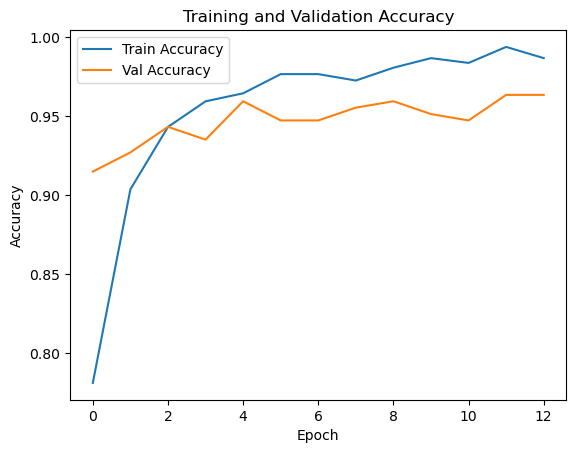

In [31]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()


# Labeling train/yawn & train/no_yawn into Closed/Open eye crops folders

In [23]:
'''
input_folder = r"C:\Users\USER\Documents\ML and Apps Project\Drowsiness_dataset_new\Drowsiness_dataset_new\train\yawn"  # or no_yawn
output_folder_open =  r"C:\Users\USER\Documents\ML and Apps Project\eye_crops"
output_folder_closed = r"C:\Users\USER\Documents\ML and Apps Project\eye_crops"

os.makedirs(output_folder_open, exist_ok=True)
os.makedirs(output_folder_closed, exist_ok=True)

mp_face_mesh = mp.solutions.face_mesh
eye_indices = {'left': [33, 133], 'right': [362, 263]}

face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)

counter = 0
for img_name in os.listdir(input_folder):
    img_path = os.path.join(input_folder, img_name)
    img = cv2.imread(img_path)
    if img is None:
        continue

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(rgb)

    if not results.multi_face_landmarks:
        continue

    h, w, _ = img.shape
    for face_landmarks in results.multi_face_landmarks:
        eyes = []
        for side in ['left', 'right']:
            pt1 = face_landmarks.landmark[eye_indices[side][0]]
            pt2 = face_landmarks.landmark[eye_indices[side][1]]
            x1, y1 = int(pt1.x * w), int(pt1.y * h)
            x2, y2 = int(pt2.x * w), int(pt2.y * h)

            margin = int(0.4 * abs(x2 - x1))
            x1, y1 = max(x1 - margin, 0), max(y1 - margin, 0)
            x2, y2 = min(x2 + margin, w), min(y2 + margin, h)

            eye_crop = img[y1:y2, x1:x2]
            if eye_crop.size == 0:
                continue

            eye_resized = cv2.resize(eye_crop, (64, 64))
            eyes.append(eye_resized)

        # Show both eyes side by side
        if len(eyes) == 2:
            combined = cv2.hconcat(eyes)
            cv2.imshow("Eye Pair", combined)
            print("Press 'o' if both eyes are open, 'c' if both are closed, 'q' to quit")
            key = cv2.waitKey(0)

            if key == ord('o'):
                for eye in eyes:
                    save_path = os.path.join(output_folder_open, f"eye_{counter}.jpg")
                    cv2.imwrite(save_path, eye)
                    counter += 1
            elif key == ord('c'):
                for eye in eyes:
                    save_path = os.path.join(output_folder_closed, f"eye_{counter}.jpg")
                    cv2.imwrite(save_path, eye)
                    counter += 1
            elif key == ord('q'):
                stop_flag = True
                break
            else:
                continue  # Skip if unknown key

            cv2.imwrite(save_path, eye_resized)
            counter += 1
if stop_flag:
    break
cv2.destroyAllWindows()
'''

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 20-21: truncated \UXXXXXXXX escape (1950084561.py, line 1)

# Training on the newly created eye crops folders 

In [25]:
DATASET_PATH = r"C:\Users\USER\Documents\ML and Apps Project\eye_crops"  
categories = {
    'open': 0,
    'closed': 1,
}
IMG_SIZE = (64, 64)

In [27]:
X = []
y = []

for category in categories:
    label = categories[category]
    folder = os.path.join(DATASET_PATH, category)
    for img_name in os.listdir(folder):
        img_path = os.path.join(folder, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        img = cv2.resize(img, IMG_SIZE)
        X.append(img)
        y.append(label)

X = np.array(X).reshape(-1, 64, 64, 1) / 255.0
y = np.array(y)


In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


In [31]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 1)),
    MaxPooling2D(2, 2),
    
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')  # Binary classification
])


C:\Users\USER\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(X_train, y_train,
                    validation_data=(X_test, y_test),
                    epochs=20,
                    batch_size=32,
                    callbacks=[early_stop])

model.save("eye_state_model_realistic.h5")


Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 83ms/step - accuracy: 0.5912 - loss: 0.6779 - val_accuracy: 0.6138 - val_loss: 0.6393
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.6700 - loss: 0.6116 - val_accuracy: 0.7561 - val_loss: 0.5380
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.7430 - loss: 0.5202 - val_accuracy: 0.7154 - val_loss: 0.5755
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.7800 - loss: 0.4921 - val_accuracy: 0.7967 - val_loss: 0.4578
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.7646 - loss: 0.4815 - val_accuracy: 0.7398 - val_loss: 0.5146
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.8002 - loss: 0.4507 - val_accuracy: 0.7967 - val_loss: 0.4380
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.8271 - loss: 0.4084 - val_accuracy: 0.7927 - val_loss: 0.4256
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.8129 - loss: 0.4161 - val_accuracy: 0.7886 - v

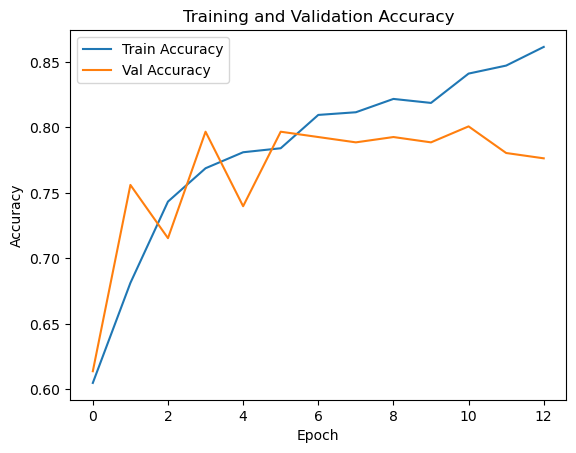

In [35]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()


# Predicting on unseen test data

In [38]:
from tensorflow.keras.models import load_model

model = load_model("eye_state_model_realistic.h5")
IMG_SIZE = (64, 64)
mp_face_mesh = mp.solutions.face_mesh

def predict_eye_state(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print("Error loading image")
        return

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    face_mesh = mp_face_mesh.FaceMesh(static_image_mode=True)
    results = face_mesh.process(rgb)

    if not results.multi_face_landmarks:
        print("No face detected.")
        return

    h, w, _ = img.shape
    eye_indices = {'left': [33, 133], 'right': [362, 263]}
    predictions = []

    for face_landmarks in results.multi_face_landmarks:
        for side in ['left', 'right']:
            pt1 = face_landmarks.landmark[eye_indices[side][0]]
            pt2 = face_landmarks.landmark[eye_indices[side][1]]
            x1, y1 = int(pt1.x * w), int(pt1.y * h)
            x2, y2 = int(pt2.x * w), int(pt2.y * h)

            margin = int(0.4 * abs(x2 - x1))
            x1, y1 = max(x1 - margin, 0), max(y1 - margin, 0)
            x2, y2 = min(x2 + margin, w), min(y2 + margin, h)

            eye_img = img[y1:y2, x1:x2]
            if eye_img.size == 0:
                continue

            eye_gray = cv2.cvtColor(eye_img, cv2.COLOR_BGR2GRAY)
            eye_resized = cv2.resize(eye_gray, IMG_SIZE)
            eye_input = eye_resized.reshape(1, 64, 64, 1) / 255.0

            prob = model.predict(eye_input)[0][0]
            label = 'Closed' if prob > 0.5 else 'Open'
            predictions.append(label)

            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img, label, (x1, y1 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    if len(predictions) == 0:
        print("No eyes detected.")
    elif predictions.count('Closed') >= 2:
        print("⚠️ Drowsiness Detected!")
    else:
        print("✅ Eyes appear open.")

    cv2.imshow("Prediction", img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

    return predictions

In [40]:
predict_eye_state(r"C:\Users\USER\Documents\ML and Apps Project\Drowsiness_dataset_new\Drowsiness_dataset_new\test\yawn\564.jpg")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
⚠️ Drowsiness Detected!


['Closed', 'Closed']